In [1]:
from comptest.image_transform import DataTransform
from comptest.configurations import (
    TIFFFILE_JPEGXL_LOSSY_CONFIGS,
    TIFFFILE_JPEGXL_LOSSY_CONFIGS_EFFORT_7_BIG,
)
from comptest.constants import DATASETS_RECONSTRUCTIONS_DIR
import shutil
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

%load_ext autoreload
%autoreload 2

In [2]:
DATASET = "Canislupus_CZM_712"
# DATASET_DIR = DATASETS_DIR / DATASET
DATASET_DIR = DATASETS_RECONSTRUCTIONS_DIR / "CIL_basic_binned_2x2" / DATASET
assert DATASET_DIR.is_dir()

INPUT_FILES = sorted(
    [
        *DATASET_DIR.glob("*.tif"),
        *DATASET_DIR.glob("*.tiff"),
    ]
)


In [3]:
from pathlib import Path

OUTPUT_DIR = Path("output")
assert OUTPUT_DIR.is_dir()

OUTPUT_QUALITY_DIR = OUTPUT_DIR / "quality_viewer"
OUTPUT_QUALITY_DIR.mkdir(exist_ok=True, parents=True)

OUT_DIR = OUTPUT_QUALITY_DIR / DATASET
OUT_DIR.mkdir(exist_ok=True, parents=True)

OUT_DIR_TIFFS = OUT_DIR / "tiffs"
OUT_DIR_TIFFS.mkdir(exist_ok=True, parents=True)


In [4]:
input_file = INPUT_FILES[len(INPUT_FILES) // 2]


In [5]:
# Copy over original
original_img_path = OUT_DIR_TIFFS / f"{input_file.stem}_original.original.tiff"
shutil.copy(input_file, original_img_path)
compressor_kwargs = {"n_jobs": None}

original_img = Image.open(OUT_DIR_TIFFS / f"{input_file.stem}_original.original.tiff")
original_img_arr = np.array(original_img)


# NOTE: We need to transform first, even lossy mode is broken for JXL f32
# TODO: Report to libjxl/imagecodecs
transform = DataTransform.infer(original_img_arr, target_range=(0, 1.0))


def _transform_image(img_path: Path, out_path: Path):
    img = Image.open(img_path)
    img_arr = np.array(img)
    img_arr = transform.apply(img_arr)
    transformed_img = Image.fromarray(img_arr)
    transformed_img.save(out_path)


_transform_image(
    original_img_path, OUT_DIR_TIFFS / f"{input_file.stem}_original.decompressed.tiff"
)

for cfg in TIFFFILE_JPEGXL_LOSSY_CONFIGS_EFFORT_7_BIG:
    # if cfg.effort != 7:
    #     continue

    compressed_output_file = OUT_DIR_TIFFS / f"{input_file.stem}_{cfg.name}.tiff"
    shutil.copy(input_file, compressed_output_file.with_suffix(".original.tiff"))

    # Transform input file
    transformed_input_file = (
        OUT_DIR_TIFFS / f"{input_file.stem}_{cfg.name}.transformed.tiff"
    )
    _transform_image(input_file, transformed_input_file)

    cfg.compressor[0](
        [transformed_input_file],
        [compressed_output_file],
        *cfg.compressor[1],
        **cfg.compressor[2] | compressor_kwargs,
    )
    cfg.decompressor[0](
        [compressed_output_file],
        [compressed_output_file.with_suffix(".decompressed.tiff")],
        *cfg.decompressor[1],
        **cfg.decompressor[2] | compressor_kwargs,
    )


In [ ]:
CROP_AREA = (560, 630, 560 + 60, 630 + 50)  # (left, upper, right, lower)
original_img = Image.open(
    OUT_DIR_TIFFS / f"{input_file.stem}_original.decompressed.tiff"
)
original_img_arr = np.array(original_img)
# transform = DataTransform.infer(original_img_arr, target_range=(0, 1.0))
# original_img_arr = transform.apply(original_img_arr)

original_img_cropped = Image.fromarray(original_img_arr).crop(CROP_AREA)
original_img_arr_cropped = np.array(original_img_cropped)
for file in sorted(OUT_DIR_TIFFS.glob("*decompressed.tiff")):
    img = Image.open(file)
    img = img.crop(CROP_AREA)
    img_arr = np.array(img)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(img_arr, vmin=0, vmax=1.0)
    ax2.imshow(img_arr - original_img_arr_cropped)
    plt.colorbar(ax2.images[0], ax=ax2, fraction=0.046, pad=0.04)
    fig.suptitle(file.stem)


In [7]:
(img_arr - original_img_arr_cropped).max()

np.float32(0.12382996)

In [64]:
from matplotlib.patches import Rectangle


def plot_quality_comparison(
    original,
    decompressed_by_distance,
    crop_area,
    *,
    overview_crop_area=None,
    vmin=0.0,
    vmax=1.0,
    diff_percentile=99.5,
):
    """
    Parameters
    ----------
    original
        Full 2D reference image.
    decompressed_by_distance
        Mapping from JPEG XL distance to decompressed 2D image.
    crop_area
        Zoom area as (left, upper, right, lower), in full-image coordinates.
    overview_crop_area
        Area of the original displayed in the overview panel, also in
        full-image coordinates. It must contain crop_area.
    """
    original = np.asarray(original)

    if original.ndim != 2:
        raise ValueError(f"Expected a 2D original image, got shape {original.shape}")

    height, width = original.shape

    def validate_area(area, name):
        left, upper, right, lower = map(int, area)

        if not (0 <= left < right <= width and 0 <= upper < lower <= height):
            raise ValueError(f"{name} {area} is outside image shape {original.shape}")

        return left, upper, right, lower

    (
        zoom_left,
        zoom_upper,
        zoom_right,
        zoom_lower,
    ) = validate_area(crop_area, "crop_area")

    if overview_crop_area is None:
        overview_left = 0
        overview_upper = 0
        overview_right = width
        overview_lower = height
    else:
        (
            overview_left,
            overview_upper,
            overview_right,
            overview_lower,
        ) = validate_area(
            overview_crop_area,
            "overview_crop_area",
        )

    if not (
        overview_left <= zoom_left < zoom_right <= overview_right
        and overview_upper <= zoom_upper < zoom_lower <= overview_lower
    ):
        raise ValueError("crop_area must be completely inside overview_crop_area")

    original_overview = original[
        overview_upper:overview_lower,
        overview_left:overview_right,
    ]

    original_zoom = original[
        zoom_upper:zoom_lower,
        zoom_left:zoom_right,
    ]
    original_zoom_float = original_zoom.astype(np.float64)

    comparisons = []

    for distance, decompressed in decompressed_by_distance.items():
        decompressed = np.asarray(decompressed)

        if decompressed.shape != original.shape:
            raise ValueError(
                f"Distance {distance:g} has shape {decompressed.shape}; "
                f"expected {original.shape}"
            )

        decompressed_zoom = decompressed[
            zoom_upper:zoom_lower,
            zoom_left:zoom_right,
        ]

        difference = decompressed_zoom.astype(np.float64) - original_zoom_float

        comparisons.append((distance, decompressed_zoom, difference))

    if not comparisons:
        raise ValueError("No decompressed images were supplied")

    absolute_differences = np.concatenate(
        [np.abs(difference).ravel() for _, _, difference in comparisons]
    )
    finite_differences = absolute_differences[np.isfinite(absolute_differences)]

    diff_limit = (
        np.percentile(finite_differences, diff_percentile)
        if finite_differences.size
        else 1.0
    )

    if not np.isfinite(diff_limit) or diff_limit <= 0:
        diff_limit = 1.0

    nrows = len(comparisons) + 1

    # The third GridSpec column is reserved for the colorbar. This prevents
    # the colorbar from resizing or shifting the error-image column.
    fig = plt.figure(
        figsize=(10, 4.0 * nrows),
    )

    grid = fig.add_gridspec(
        nrows=nrows,
        ncols=3,
        width_ratios=(1, 1, 0.025),
        left=0.02,
        right=0.97,
        bottom=0.02,
        top=0.98,
        wspace=0.02,
        hspace=0.10,
    )

    axes = np.empty((nrows, 2), dtype=object)

    for row in range(nrows):
        axes[row, 0] = fig.add_subplot(grid[row, 0])
        axes[row, 1] = fig.add_subplot(grid[row, 1])

    colorbar_axis = fig.add_subplot(grid[1:, 2])

    # Original zoom on the left.
    axes[0, 0].imshow(
        original_zoom,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        aspect="equal",
    )
    axes[0, 0].set_title("Original zoom")

    # Cropped original overview on the right.
    axes[0, 1].imshow(
        original_overview,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        aspect="equal",
    )

    # Convert the zoom position from full-image coordinates to coordinates
    # relative to the cropped overview.
    outline_left = zoom_left - overview_left
    outline_upper = zoom_upper - overview_upper

    axes[0, 1].add_patch(
        Rectangle(
            (outline_left - 0.5, outline_upper - 0.5),
            zoom_right - zoom_left,
            zoom_lower - zoom_upper,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
    )
    axes[0, 1].set_title("Original")

    difference_image = None

    for row, (distance, decompressed_zoom, difference) in enumerate(
        comparisons,
        start=1,
    ):
        axes[row, 0].imshow(
            decompressed_zoom,
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            aspect="equal",
        )
        axes[row, 0].set_title(f"Distance = {distance:g}")

        difference_image = axes[row, 1].imshow(
            difference,
            cmap="RdBu_r",
            vmin=-diff_limit,
            vmax=diff_limit,
            aspect="equal",
        )
        axes[row, 1].set_title(f"Difference — Distance = {distance:g}")

    for axis in axes.flat:
        axis.set_axis_off()
        axis.set_anchor("N")

    fig.colorbar(
        difference_image,
        cax=colorbar_axis,
        label="Pixel difference (data range 0–1)",
    )

    return fig, axes

In [65]:
DISTANCES = [1.0, 5.0]

configs_by_distance = {
    cfg.distance: cfg for cfg in TIFFFILE_JPEGXL_LOSSY_CONFIGS_EFFORT_7_BIG
}

missing_distances = [
    distance for distance in DISTANCES if distance not in configs_by_distance
]

if missing_distances:
    raise ValueError(
        f"Distances not present in the JPEG XL configuration: {missing_distances}"
    )


def load_image_array(path):
    if not path.is_file():
        raise FileNotFoundError(path)

    with Image.open(path) as image:
        return np.array(image)


original_path = OUT_DIR_TIFFS / f"{input_file.stem}_original.decompressed.tiff"
original_img_arr = load_image_array(original_path)

decompressed_by_distance = {}

for distance in DISTANCES:
    cfg = configs_by_distance[distance]

    decompressed_path = (
        OUT_DIR_TIFFS / f"{input_file.stem}_{cfg.name}.decompressed.tiff"
    )

    decompressed_by_distance[distance] = load_image_array(decompressed_path)

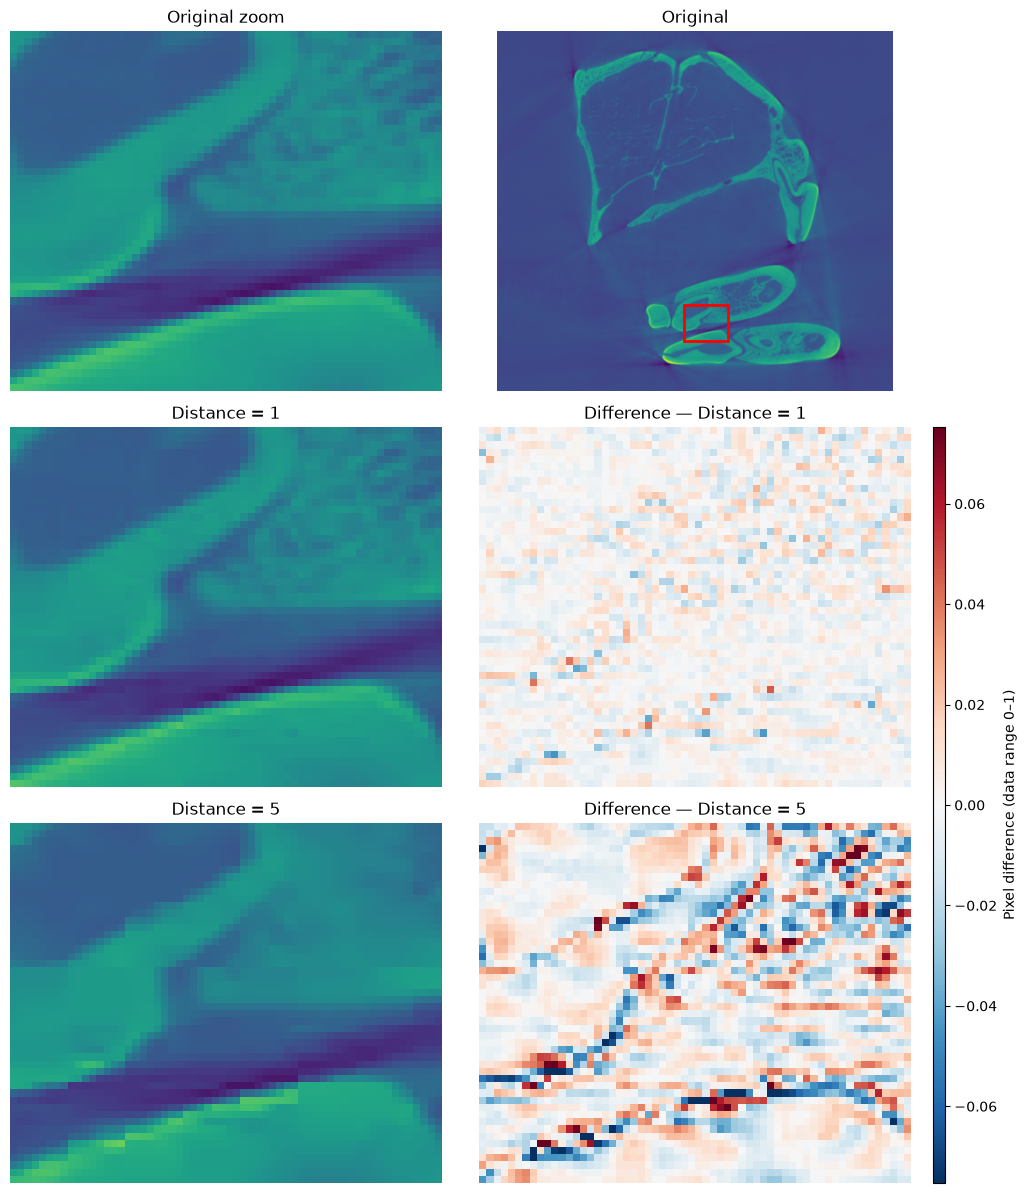

In [66]:
# Both areas use full-image coordinates.
# (left, upper, right, lower)
OVERVIEW_CROP_AREA = (300, 250, 850, 750)

fig, axes = plot_quality_comparison(
    original_img_arr,
    decompressed_by_distance,
    CROP_AREA,
    overview_crop_area=OVERVIEW_CROP_AREA,
)

plt.show()